In [1]:
#####     KGE Components and Clustering     #####
import numpy as np
import pandas as pd
from joblib import load
import rasterio
import warnings

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)
rng = np.random.default_rng(seed=42)

def flipImage(tiff: np.ndarray, shift=180) -> np.ndarray:
    """Flip latitude and shift longitude from original raster layout to 0-360° layout."""
    flipped = np.flip(tiff, axis=0)  # 纬度翻转
    shifted = np.roll(flipped, -shift, axis=1)  # 经度平移
    return shifted


In [2]:
### ----- Load ESACCI V7 / CMIP6 / Koppen ----- ###
ESAv7_data = np.load("./Data/AGBC_ESAv7.npz")
ESAv7_std = np.load("./Data/AGBCsd_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(val.astype(np.float32)) for k, val in ESAv7_data.items()}
ESAv7_std = {k.title(): flipImage(val.astype(np.float32)) for k, val in ESAv7_std.items()}
print("ESACCI V7:", ESAv7_data.keys())

ESA_data = ESAv7_data["Mean"].copy()
ESA_std = ESAv7_std["Mean"].copy()

CMIP_set = np.load("./Data/CMIP6_AGBC.npz")
modelNum = len(CMIP_set)
modelNames = list(CMIP_set.keys())
CMIP_list0 = [np.array(val, dtype=np.float32) for val in CMIP_set.values()]
print(f"CMIP Models: {modelNum}")
print(modelNames)

with rasterio.open("./Data/Koppen_2010.tif", "r") as src:
    Koppen = src.read(1).astype(np.float32)
    Koppen = flipImage(Koppen)

ValidMask = (Koppen > 0) & (ESA_data > 0)
Koppen[~ValidMask] = np.nan
ESA_data[~ValidMask] = np.nan
ESA_std[~ValidMask] = np.nan
for data in CMIP_list0:
    data[~ValidMask] = np.nan


ESACCI V7: dict_keys(['2010', '2011', '2012', '2015', 'Mean'])
CMIP Models: 30
['ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CanESM5', 'CESM2-FV2', 'CESM2-WACCM-FV2', 'CESM2-WACCM', 'CESM2', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-ESM2-1', 'E3SM-1-1-ECA', 'E3SM-1-1', 'EC-Earth3-CC', 'EC-Earth3-Veg-LR', 'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'IPSL-CM6A-LR-INCA', 'IPSL-CM6A-LR', 'KIOST-ESM', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'NorCPM1', 'NorESM2-LM', 'NorESM2-MM', 'SAM0-UNICON', 'TaiESM1', 'UKESM1-0-LL', 'UKESM1-1-LL']


In [3]:
### ----- Reuse Tree Mask & Build Climate Zone Masks ----- ###
CMIP_data0: np.ndarray = np.stack(CMIP_list0, axis=0)

TreeMask = load("./Data/Masks/treemask.joblib").astype(np.float32)
TreeMask[TreeMask == 0] = np.nan

ESA_datat = ESA_data * TreeMask
ESA_stdt = ESA_std * TreeMask
CMIP_datat = CMIP_data0 * TreeMask

CliDict = {
    "Af": [1],
    "Am": [2],
    "Aw": [3],
    "BW": [4, 5],
    "BS": [6, 7],
    "Cs": [8, 9, 10],
    "Cw": [11, 12, 13],
    "Cf": [14, 15, 16],
    "Ds": [17, 18, 19, 20],
    "Dw": [21, 22, 23, 24],
    "Df": [25, 26, 27, 28],
    "ET": [29],
}
CliMask = [np.isin(Koppen, ids) for ids in CliDict.values()]

ZoneMasks = {
    "Global": np.isfinite(ESA_datat),
    "Tropical": CliMask[0] | CliMask[1] | CliMask[2],
    "Temperate": CliMask[5] | CliMask[6] | CliMask[7],
    "Boreal": CliMask[8] | CliMask[9] | CliMask[10],
}
ZoneMasks = {name: (mask & np.isfinite(ESA_datat)) for name, mask in ZoneMasks.items()}
zone_names = list(ZoneMasks.keys())

print(ZoneMasks.keys())

dict_keys(['Global', 'Tropical', 'Temperate', 'Boreal'])


In [4]:
### ----- Calculate KGE and its components ----- ###

def cal_kge_components(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """Return KGE and its three components: r, beta, gamma.

    KGE = `1 - sqrt((r-1)^2 + (β-1)^2 + (γ-1)^2)`,
    where r is the correlation coefficient,
    beta is the bias ratio (mean pred / mean obs),
    and gamma is the variability ratio (std pred / std obs).
    """
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    if y_true.size < 3:
        return {"r": np.nan, "beta": np.nan, "gamma": np.nan, "KGE": np.nan, "n": y_true.size}

    true_std = np.std(y_true)
    pred_std = np.std(y_pred)
    true_mean = np.mean(y_true)
    pred_mean = np.mean(y_pred)

    r = np.corrcoef(y_true, y_pred)[0, 1] if true_std > 0 and pred_std > 0 else np.nan
    beta = pred_mean / true_mean if true_mean != 0 else np.nan
    gamma = pred_std / true_std if true_std > 0 else np.nan
    kge = 1 - np.sqrt((r - 1)**2 + (beta - 1)**2 + (gamma - 1)**2)
    return {"r": r, "beta": beta, "gamma": gamma, "KGE": kge, "n": y_true.size}


In [5]:
# --- MME KGE components --- #
print("MME KGE components")
CMIP_mean = np.nanmean(CMIP_datat, axis=0)
for zone_name, zone_mask in ZoneMasks.items():
    comp = cal_kge_components(ESA_datat[zone_mask], CMIP_mean[zone_mask])
    print(
        f" {zone_name:<10s} KGE={comp['KGE']:.4f},  "
        f"r={comp['r']:.4f},  beta={comp['beta']:.4f},  gamma={comp['gamma']:.4f},  n={comp['n']}"
    )

# --- Model KGE components --- #
rows = []
for i, modelName in enumerate(modelNames):
    modelData = CMIP_datat[i]
    row = {"Model": modelName}
    print(f"\n{i:02d} {modelName:<18s}")
    for zone_name, zone_mask in ZoneMasks.items():
        mask = zone_mask & (modelData > 0)
        comp = cal_kge_components(ESA_datat[mask], modelData[mask])
        for metric in ["r", "beta", "gamma", "KGE", "n"]:
            row[f"{zone_name}_{metric}"] = comp[metric]
        print(
            f"  {zone_name:<10s} KGE={comp['KGE']:.4f},  "
            f"r={comp['r']:.4f},  beta={comp['beta']:.4f},  gamma={comp['gamma']:.4f},  n={comp['n']}"
        )
    rows.append(row)

kge_df = pd.DataFrame(rows).set_index("Model")
display(kge_df.head())


MME KGE components
 Global     KGE=0.7669,  r=0.8099,  beta=1.1279,  gamma=1.0426,  n=3518
 Tropical   KGE=0.6708,  r=0.7540,  beta=1.1904,  gamma=0.8923,  n=1132
 Temperate  KGE=0.1883,  r=0.2645,  beta=1.2120,  gamma=0.7299,  n=398
 Boreal     KGE=0.4437,  r=0.5226,  beta=1.0093,  gamma=0.7145,  n=1951

00 ACCESS-ESM1-5     
  Global     KGE=0.2395,  r=0.6830,  beta=1.6892,  gamma=1.0534,  n=3518
  Tropical   KGE=0.5448,  r=0.6847,  beta=1.3251,  gamma=1.0463,  n=1132
  Temperate  KGE=-0.3715,  r=0.2611,  beta=2.0222,  gamma=1.5386,  n=398
  Boreal     KGE=-0.2460,  r=0.5518,  beta=2.0626,  gamma=1.4717,  n=1951

01 BCC-CSM2-MR       
  Global     KGE=0.6198,  r=0.6853,  beta=1.0097,  gamma=0.7869,  n=3513
  Tropical   KGE=0.5432,  r=0.6877,  beta=0.8818,  gamma=0.6883,  n=1131
  Temperate  KGE=0.2103,  r=0.2283,  beta=1.1459,  gamma=1.0828,  n=398
  Boreal     KGE=0.3509,  r=0.3882,  beta=1.1464,  gamma=1.1601,  n=1947

02 BCC-ESM1          
  Global     KGE=0.6059,  r=0.6737,  beta

C:\Users\Admin\AppData\Local\Temp\ipykernel_24688\2631712717.py:3: RuntimeWarning: Mean of empty slice
  CMIP_mean = np.nanmean(CMIP_datat, axis=0)


,Global_r,Global_beta,Global_gamma,Global_KGE,Global_n,Tropical_r,Tropical_beta,Tropical_gamma,Tropical_KGE,Tropical_n,Temperate_r,Temperate_beta,Temperate_gamma,Temperate_KGE,Temperate_n,Boreal_r,Boreal_beta,Boreal_gamma,Boreal_KGE,Boreal_n
Model,,,,,,,,,,,,,,,,,,,,
ACCESS-ESM1-5,0.683018,1.689200,1.053397,0.239523,3518,0.684697,1.325094,1.046265,0.544761,1132,0.261064,2.022162,1.538644,-0.371488,398,0.551792,2.062635,1.471669,-0.246016,1951
BCC-CSM2-MR,0.685282,1.009668,0.786899,0.619799,3513,0.687659,0.881830,0.688299,0.543187,1131,0.228301,1.145890,1.082797,0.210279,398,0.388220,1.146379,1.160113,0.350895,1947
BCC-ESM1,0.673666,1.109905,0.808382,0.605931,3518,0.626262,0.982547,0.669197,0.500585,1132,0.123929,1.216448,1.033288,0.096973,398,0.393881,1.247903,1.165882,0.324461,1951
CanESM5,0.359437,1.126445,1.003242,0.347068,3518,0.116827,0.956458,0.960050,0.114852,1132,0.062016,1.411091,1.110751,-0.030086,398,0.229441,1.263719,1.632169,-0.030993,1951
CESM2-FV2,0.788489,1.325410,1.275275,0.524180,3518,0.776823,1.317230,1.233469,0.547285,1132,0.368690,1.191530,1.318418,0.267452,398,0.405708,1.365415,1.355969,0.216786,1951


**Cluster models with KGE components**

The clustering features below use the three KGE components (`r`, `beta`, `gamma`) for each analysis zone.
The aggregated `KGE` score is kept for interpretation, but it is not used as a clustering input.


In [6]:
### ----- Cluster models by KGE components, not by aggregated KGE ----- ###
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cluster_metrics = ["r", "beta", "gamma"]
feature_cols = [f"{zone}_{metric}" for zone in zone_names for metric in cluster_metrics]
X = kge_df[feature_cols].replace([np.inf, -np.inf], np.nan)
if X.isna().any().any():
    print("Warning: missing component values were filled by column means before clustering.")
    X = X.fillna(X.mean())

#scaler = StandardScaler()
#X_scaled = scaler.fit_transform(X)  # 进行标准化
X_scaled = X  # 不进行标准化

def find_optimal_clusters(data: np.ndarray, min_k: int, max_k: int):
    max_k = min(max_k, data.shape[0] - 1)
    if min_k > max_k:
        raise ValueError("Not enough samples to test clustering.")
    scores = []
    for k in range(min_k, max_k + 1):
        labels = AgglomerativeClustering(n_clusters=k).fit_predict(data)
        score = silhouette_score(data, labels)
        scores.append({"k": k, "silhouette": score})
    score_df = pd.DataFrame(scores)
    best = score_df.loc[score_df["silhouette"].idxmax()]
    return int(best["k"]), float(best["silhouette"]), score_df

min_k, max_k = 2, 5  # Cluster K range
optimal_k, max_score, score_df = find_optimal_clusters(X_scaled, min_k, max_k)
print(f"Optimal K = {optimal_k},  Max score: {max_score:.4f}")
display(score_df)

# --- Set Cluster K --- #
cluster_k = 4
print(f"Cluster K = {cluster_k}")

final_model = AgglomerativeClustering(n_clusters=cluster_k)
cluster_result = final_model.fit_predict(X_scaled)

result_path = "./cluster.csv"
cluster_df = kge_df.copy()
cluster_df.insert(0, "Cluster", cluster_result + 1)
cluster_df = cluster_df.sort_values("Model")
cluster_df.to_csv(result_path, header=True, encoding="utf-8")
print(f"Result saved to: {result_path}")

display(cluster_df)


Optimal K = 4,  Max score: 0.3581


,k,silhouette
0,2,0.339663
1,3,0.350096
2,4,0.358090
3,5,0.329632


Cluster K = 4
Result saved to: ./cluster.csv


,Cluster,Global_r,Global_beta,Global_gamma,Global_KGE,Global_n,Tropical_r,Tropical_beta,Tropical_gamma,Tropical_KGE,...,Temperate_r,Temperate_beta,Temperate_gamma,Temperate_KGE,Temperate_n,Boreal_r,Boreal_beta,Boreal_gamma,Boreal_KGE,Boreal_n
Model,,,,,,,,,,,,,,,,,,,,,
ACCESS-ESM1-5,1,0.683018,1.689200,1.053397,0.239523,3518,0.684697,1.325094,1.046265,0.544761,...,0.261064,2.022162,1.538644,-0.371488,398,0.551792,2.062635,1.471669,-0.246016,1951
BCC-CSM2-MR,1,0.685282,1.009668,0.786899,0.619799,3513,0.687659,0.881830,0.688299,0.543187,...,0.228301,1.145890,1.082797,0.210279,398,0.388220,1.146379,1.160113,0.350895,1947
BCC-ESM1,1,0.673666,1.109905,0.808382,0.605931,3518,0.626262,0.982547,0.669197,0.500585,...,0.123929,1.216448,1.033288,0.096973,398,0.393881,1.247903,1.165882,0.324461,1951
CESM2,1,0.778709,1.337624,1.249664,0.525350,3518,0.755773,1.326306,1.190568,0.550068,...,0.380473,1.078711,1.332911,0.292300,398,0.391015,1.422922,1.279740,0.207548,1951
CESM2-FV2,1,0.788489,1.325410,1.275275,0.524180,3518,0.776823,1.317230,1.233469,0.547285,...,0.368690,1.191530,1.318418,0.267452,398,0.405708,1.365415,1.355969,0.216786,1951
CESM2-WACCM,1,0.787152,1.322782,1.277093,0.524318,3518,0.763537,1.342875,1.193532,0.540726,...,0.386664,1.072519,1.348516,0.290844,398,0.394770,1.362887,1.273649,0.243115,1951
CESM2-WACCM-FV2,1,0.781631,1.310096,1.241174,0.550545,3518,0.769387,1.290688,1.200158,0.578402,...,0.370235,1.160265,1.289045,0.288779,398,0.404546,1.366098,1.351426,0.217636,1951
CMCC-CM2-SR5,2,0.746219,1.210043,1.712023,0.215462,3518,0.687209,1.362085,1.878798,-0.000615,...,0.170058,1.236023,1.638724,-0.073536,398,0.454900,0.997933,1.344004,0.355425,1951
CMCC-ESM2,2,0.776554,1.250430,1.761633,0.167697,3518,0.732415,1.434586,1.894938,-0.030234,...,0.155964,1.213685,1.638471,-0.079677,398,0.481240,1.011038,1.334120,0.382854,1951


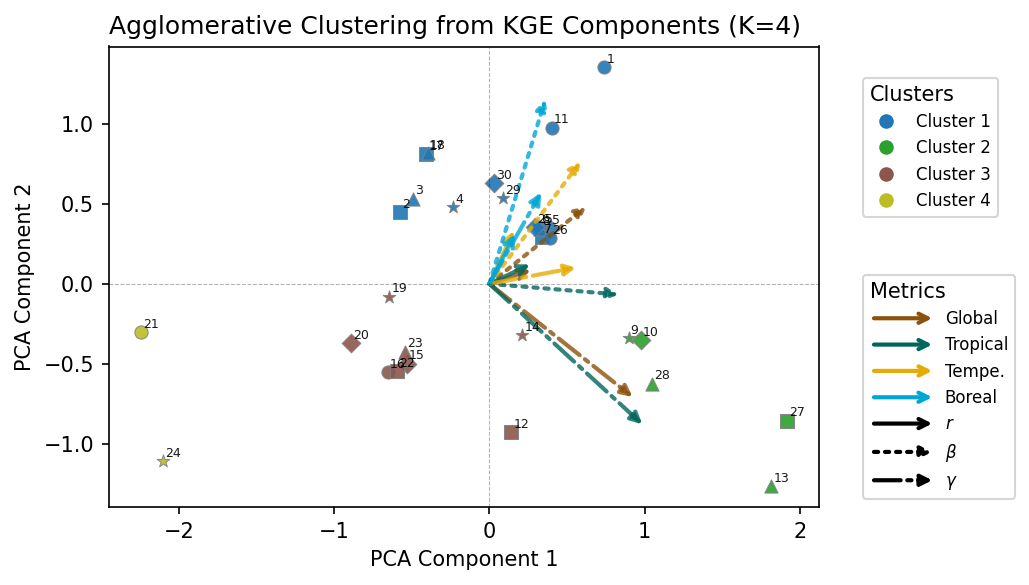

In [7]:
### ----- PCA visualization of component-based clustering ----- ###
from matplotlib.patches import FancyArrowPatch
from matplotlib.legend_handler import HandlerPatch

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)
comX, comY = principal_components[:, 0], principal_components[:, 1]

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)

# --- Model Scatter --- #
# Model colors identify clusters. Marker shapes are reused only to separate nearby points visually.
cluster_palette = plt.get_cmap("tab10")(np.linspace(0, 0.8, cluster_k))
markers = ["o", "s", "^", "*", "D"]
for i, modelName in enumerate(modelNames):
    ax.scatter(
        comX[i], comY[i], s=40,
        facecolor=cluster_palette[cluster_result[i]],
        edgecolor="gray", linewidth=0.5,
        marker=markers[i % len(markers)], alpha=0.9,
    )
    ax.annotate(str(i+1), (comX[i], comY[i]), xytext=(1, 2),
        textcoords="offset points", fontsize=6, alpha=0.9
    )

# --- PCA loadings --- #
# Climate zone is encoded by arrow color
# KGE component is encoded by line and arrow style
zone_colors = {
    "Global": "#8C510A",
    "Tropical": "#01665E",
    "Tempe.": "#E6AB02",
    "Boreal": "#00A6D6",
}
metric_styles = {
    "r": {"linestyle": "-", "arrowstyle": "->"},
    "beta": {"linestyle": ":", "arrowstyle": "-|>"},
    "gamma": {"linestyle": "-.", "arrowstyle": "-|>"},
}

zone_labels = {"Global": "Global", "Tropical": "Tropical", "Temperate": "Tempe.", "Boreal": "Boreal"}
metric_labels = {"r": r"$r$", "beta": r"$\beta$", "gamma": r"$\gamma$"}
loading_linewidth = 2.0

loadings = pca.components_.T
arrow_scale = 2.0
for idx, feature in enumerate(feature_cols):
    zone, metric = feature.rsplit("_", 1)
    dx, dy = loadings[idx, 0] * arrow_scale, loadings[idx, 1] * arrow_scale
    style = metric_styles[metric]
    arrow = FancyArrowPatch(
        (0, 0), (dx, dy),
        arrowstyle=style["arrowstyle"], mutation_scale=11,
        linewidth=loading_linewidth, linestyle=style["linestyle"],
        color=zone_colors[zone_labels[zone]], alpha=0.8,
        shrinkA=0, shrinkB=0,
    )
    ax.add_patch(arrow)

# --- Legend --- #
def make_legend_arrow(legend, orig_handle, xdescent, ydescent, width, height, fontsize):
    return FancyArrowPatch(
        (xdescent, ydescent + 0.5*height),
        (xdescent + width, ydescent + 0.5*height),
        arrowstyle=orig_handle.get_arrowstyle(), mutation_scale=11,
        linewidth=loading_linewidth, linestyle=orig_handle.get_linestyle(),
        color=orig_handle.get_edgecolor(),
    )

zone_handles = [
    FancyArrowPatch((0, 0), (1, 0), arrowstyle="->", mutation_scale=11,
                    linewidth=loading_linewidth, color=color, label=zone)
    for zone, color in zone_colors.items()
]
metric_handles = [
    FancyArrowPatch((0, 0), (1, 0), arrowstyle=style["arrowstyle"], mutation_scale=11,
                    linewidth=loading_linewidth, linestyle=style["linestyle"],
                    color="black", label=metric_labels[metric])
    for metric, style in metric_styles.items()
]
loading_handles = zone_handles + metric_handles

cluster_handles = [
    Line2D([0], [0], marker="o", color="w", label=f"Cluster {c + 1}",
           markerfacecolor=cluster_palette[c % len(cluster_palette)],
           markeredgecolor="white", markersize=8)
    for c in range(cluster_k)
]
legend_model = ax.legend(
    handles=cluster_handles, title="Clusters",
    loc="upper left", bbox_to_anchor=(1.05, 0.95), fontsize=8,
)
legend_model._legend_box.align = "left"
ax.add_artist(legend_model)

legend_metrics = ax.legend(
    handles=loading_handles, title="Metrics",
    loc="lower left", bbox_to_anchor=(1.05, 0.0), fontsize=8,
    handlelength=4, handletextpad=0.5,
    handler_map={FancyArrowPatch: HandlerPatch(patch_func=make_legend_arrow)},
)
legend_metrics._legend_box.align = "left"

ax.axhline(0, color="black", alpha=0.3, linestyle="--", linewidth=0.5)
ax.axvline(0, color="black", alpha=0.3, linestyle="--", linewidth=0.5)
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_title(f"Agglomerative Clustering from KGE Components (K={cluster_k})", loc="left")

plt.tight_layout()
#fig.savefig("./_tmp_fig8_cluster_preview.png", dpi=200, bbox_inches="tight")
plt.show(fig)  # fig 5
plt.close(fig)


Clustering Result:
Cluster 1 (N=15):  ACCESS-ESM1-5,  BCC-CSM2-MR,  BCC-ESM1,  CanESM5,  CESM2-FV2,  CESM2-WACCM-FV2,  CESM2-WACCM,  CESM2,  CNRM-ESM2-1,  INM-CM4-8,  INM-CM5-0,  NorESM2-LM,  NorESM2-MM,  UKESM1-0-LL,  UKESM1-1-LL
Cluster 2 (N=5):  CMCC-CM2-SR5,  CMCC-ESM2,  E3SM-1-1,  SAM0-UNICON,  TaiESM1
Cluster 3 (N=8):  E3SM-1-1-ECA,  EC-Earth3-CC,  EC-Earth3-Veg-LR,  GFDL-ESM4,  IPSL-CM6A-LR-INCA,  IPSL-CM6A-LR,  MPI-ESM-1-2-HAM,  MPI-ESM1-2-LR
Cluster 4 (N=2):  KIOST-ESM,  NorCPM1


,Global_r,Global_beta,Global_gamma,Tropical_r,Tropical_beta,Tropical_gamma,Temperate_r,Temperate_beta,Temperate_gamma,Boreal_r,Boreal_beta,Boreal_gamma
Cluster,,,,,,,,,,,,
1,0.674324,1.287382,1.074546,0.599528,1.193754,0.931232,0.262779,1.416571,1.292870,0.404101,1.368909,1.263378
2,0.742083,1.334454,2.101380,0.667284,1.706409,2.104569,0.131765,1.384572,1.628936,0.319459,0.810994,1.164925
3,0.626275,0.875022,1.189947,0.508215,1.037187,1.099505,-0.000807,0.915379,1.079609,0.208093,0.632025,0.856916
4,0.142628,0.244481,0.512133,0.116609,0.209641,0.445285,-0.160402,0.344560,0.605924,0.013703,0.244174,0.590520


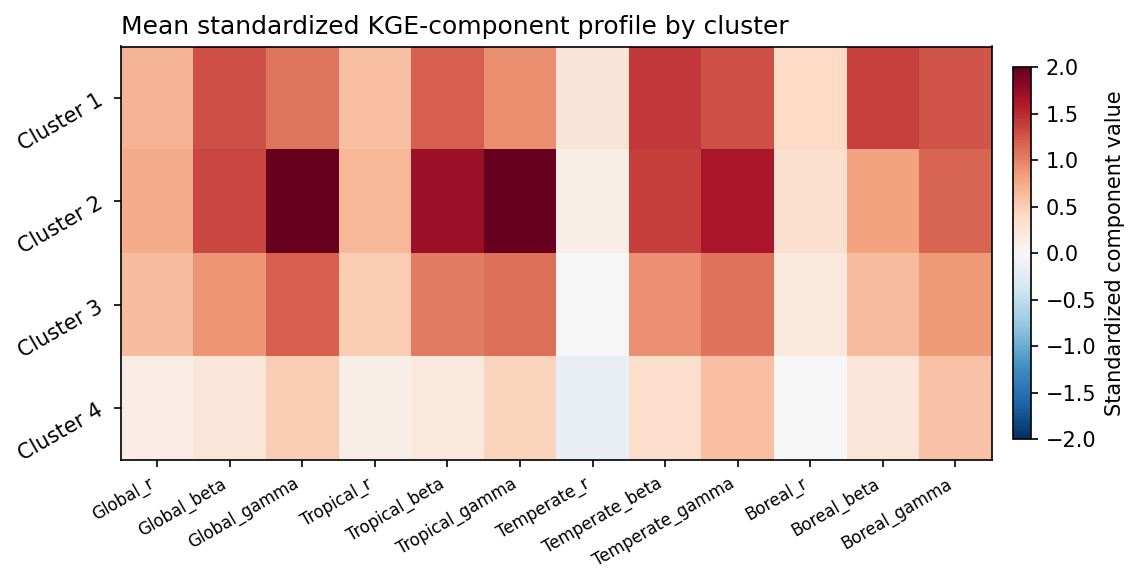

In [8]:
### ----- Cluster summaries and component profiles ----- ###
print("Clustering Result:")
for c in range(cluster_k):
    group = [modelNames[j] for j in range(modelNum) if cluster_result[j] == c]
    print(f"Cluster {c + 1} (N={len(group)}):  {',  '.join(group)}")

profile = cluster_df.groupby("Cluster")[feature_cols].mean()
display(profile)

fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
img = ax.imshow(profile.values, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_yticks(np.arange(profile.shape[0]), labels=[f"Cluster {i}" for i in profile.index], rotation=30)
ax.set_xticks(np.arange(len(feature_cols)), labels=feature_cols, rotation=30, ha="right", fontsize=8)
ax.set_title("Mean standardized KGE-component profile by cluster", loc="left")
cbar = plt.colorbar(img, ax=ax, shrink=0.9, pad=0.02)
cbar.set_label("Standardized component value")

plt.tight_layout()
plt.show()
plt.close(fig)


Model Num: 30,  Land Model: 15


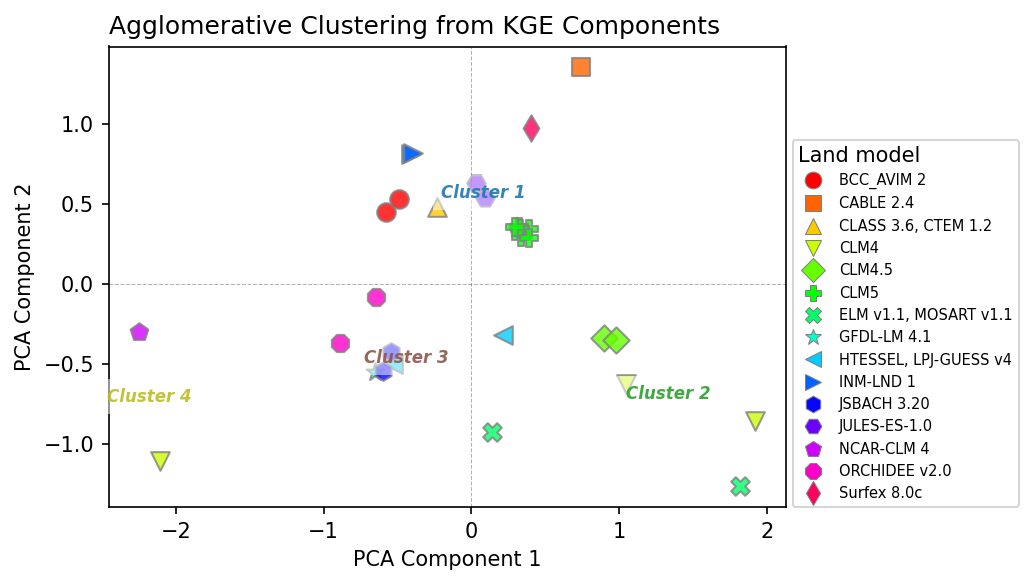

In [9]:
LandModel = np.asarray([
    "CABLE 2.4",
    "BCC_AVIM 2",
    "BCC_AVIM 2",
    "CLASS 3.6, CTEM 1.2",
    "CLM5",
    "CLM5",
    "CLM5",
    "CLM5",
    "CLM4.5",
    "CLM4.5",
    "Surfex 8.0c",
    "ELM v1.1, MOSART v1.1",
    "ELM v1.1, MOSART v1.1",
    "HTESSEL, LPJ-GUESS v4",
    "HTESSEL, LPJ-GUESS v4",
    "GFDL-LM 4.1",
    "INM-LND 1",
    "INM-LND 1",
    "ORCHIDEE v2.0",
    "ORCHIDEE v2.0",
    "NCAR-CLM 4",
    "JSBACH 3.20",
    "JSBACH 3.20",
    "CLM4",
    "CLM5",
    "CLM5",
    "CLM4",
    "CLM4",
    "JULES-ES-1.0",
    "JULES-ES-1.0",
])

unique = np.unique(LandModel)
print(f"Model Num: {len(LandModel)},  Land Model: {len(unique)}")

if len(LandModel) != len(modelNames):
    raise ValueError(f"LandModel length ({len(LandModel)}) does not match modelNames length ({len(modelNames)}).")

model_palette = plt.get_cmap("hsv")(np.linspace(0, 0.95, len(unique)))
land_markers = ["o", "s", "^", "v", "D", "P", "X", "*", "<", ">", "h", "H", "p", "8", "d"]
land_model_style = {
    land_model: {
        "color": model_palette[i],
        "marker": land_markers[i % len(land_markers)],
    }
    for i, land_model in enumerate(unique)
}

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)

for land_model in unique:
    idx = LandModel == land_model
    style = land_model_style[land_model]
    ax.scatter(
        comX[idx], comY[idx], s=80, color=style["color"], edgecolor="gray",
        marker=style["marker"], alpha=0.8, label=land_model,
    )

land_handles = [
    Line2D([0], [0], marker=land_model_style[land_model]["marker"], color="white",
           label=land_model, markerfacecolor=land_model_style[land_model]["color"],
           markeredgecolor="gray", markeredgewidth=0.5, markersize=8)
    for land_model in unique
]
legend_land = ax.legend(
    handles=land_handles, title="Land model",
    loc="lower left", bbox_to_anchor=(1.01, 0.0), fontsize=7,
    ncol=1, borderaxespad=0.0,
)
legend_land._legend_box.align = "left"

for i in range(cluster_k):
    idx = (cluster_result == i)
    if not np.any(idx):  continue
    ax.text(
        np.mean(comX[idx]), np.mean(comY[idx]), f"Cluster {i+1}",
        color=cluster_palette[i], fontsize=8, alpha=0.9,
        fontstyle="italic", fontweight="bold", ha="center", va="center",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.5),
    )

ax.axhline(0, color="black", alpha=0.3, linestyle="--", linewidth=0.5)
ax.axvline(0, color="black", alpha=0.3, linestyle="--", linewidth=0.5)
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_title("Agglomerative Clustering from KGE Components", loc="left")

plt.tight_layout()
plt.show()
plt.close(fig)
